#Preprocessing Dataset Student Performance

Nama: Disa Nastha Gesiya

Mata kuliah: Data Mining

Program Studi : Staterkom

## 1. Pendahuluan

Preprocessing data merupakan tahap persiapan data sebelum digunakan untuk analisis lebih lanjut. Notebook ini menggunakan dataset **Student Performance** yang memuat informasi siswa, kondisi keluarga dan sekolah, kebiasaan, ketidakhadiran, serta nilai akademik.

Tahapan yang dilakukan meliputi pemuatan data, pemeriksaan kualitas data, deteksi dan evaluasi outlier, encoding variabel kategorikal, standardisasi variabel numerik terpilih, validasi, dan penyimpanan hasil.

**Catatan:** nilai yang terdeteksi sebagai outlier tidak otomatis salah. Pada notebook ini, outlier dievaluasi dan dipertahankan apabila tidak ada bukti bahwa nilainya merupakan kesalahan pencatatan.

## 2. Import library

Library `pandas` digunakan untuk mengelola data, `matplotlib` dan `seaborn` untuk visualisasi, sedangkan `StandardScaler` digunakan untuk standardisasi. Library `ucimlrepo` digunakan untuk mengambil dataset dari UCI Machine Learning Repository.

In [20]:
!pip -q install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 3. Memuat dataset

Dataset diambil dari UCI Machine Learning Repository dengan ID 320. Dataset ini menyediakan data performa siswa dalam mata pelajaran matematika dan bahasa Portugis. Untuk notebook ini, data yang dimuat mengikuti penggabungan fitur dan target dari dataset yang diambil.

In [21]:
dataset = fetch_ucirepo(id=320)

df_raw = pd.concat(
    [dataset.data.features, dataset.data.targets],
    axis=1
)

# Menampilkan ukuran dan beberapa baris awal
print("Ukuran dataset:", df_raw.shape)
display(df_raw.head())

Ukuran dataset: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


**Interpretasi:** dataset yang digunakan berisi 649 baris dan 33 kolom pada output awal. Baris merepresentasikan catatan siswa, sedangkan kolom merepresentasikan karakteristik siswa dan nilai akademik.

## 4. Pemeriksaan awal data

Pemeriksaan awal dilakukan untuk memahami struktur dataset dan mengidentifikasi masalah kualitas data, seperti tipe data yang tidak sesuai, nilai kosong, atau catatan duplikat.

In [22]:
# Informasi kolom dan tipe data
df_raw.info()

# Jumlah missing values
print("\nJumlah missing values:", df_raw.isnull().sum().sum())
display(df_raw.isnull().sum().sort_values(ascending=False).head(10))

# Jumlah baris duplikat
print("\nJumlah data duplikat:", df_raw.duplicated().sum())

# Statistik deskriptif
display(df_raw.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0



Jumlah data duplikat: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,649,2,GP,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,649,2,F,383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,649.0,NaN,NaN,NaN,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649,2,U,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,649,2,GT3,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,649,2,T,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,649.0,NaN,NaN,NaN,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,NaN,NaN,NaN,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649,5,other,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,649,5,other,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretasi hasil pemeriksaan awal:**

Berdasarkan output yang diperoleh pada sesi pengerjaan, dataset memiliki **649 baris dan 33 kolom**, terdiri atas **16 kolom numerik dan 17 kolom kategorikal**. Tidak ditemukan missing values maupun baris duplikat. Karena itu, imputasi missing values dan penghapusan duplikat tidak diperlukan pada data ini.

Jika output berbeda ketika notebook dijalankan ulang, gunakan hasil aktual yang ditampilkan oleh kode.

## 5. Menyiapkan salinan data

Data asli disimpan dalam `df_raw`. Salinan `df_clean` digunakan untuk proses berikutnya agar data awal tetap tersedia sebagai pembanding. Pada tahap ini tidak ada baris yang dihapus karena pemeriksaan awal tidak menemukan duplikat atau missing values.

In [23]:
df_clean = df_raw.copy()

print("Ukuran data setelah penyiapan:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplikat:", df_clean.duplicated().sum())

Ukuran data setelah penyiapan: (649, 33)
Missing values: 0
Duplikat: 0


## 6. Deteksi outlier dengan boxplot dan metode IQR

Outlier diperiksa pada variabel `age`, `absences`, `G1`, `G2`, dan `G3`. Variabel tersebut dipilih untuk melihat nilai usia, jumlah ketidakhadiran, serta nilai akademik.

Metode Interquartile Range (IQR) menggunakan kuartil pertama (Q1) dan kuartil ketiga (Q3). Nilai di bawah `Q1 − 1,5 × IQR` atau di atas `Q3 + 1,5 × IQR` ditandai sebagai outlier untuk diperiksa lebih lanjut. Penandaan ini tidak otomatis berarti nilainya salah.

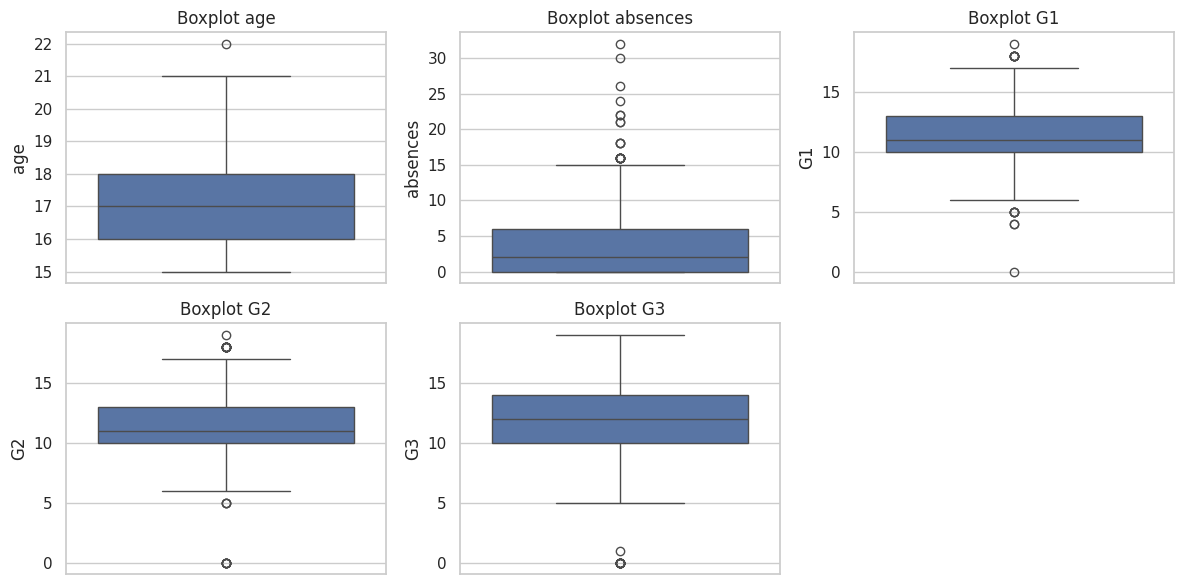

In [24]:
kolom_numerik = ["age", "absences", "G1", "G2", "G3"]

plt.figure(figsize=(12, 6))

for i, kolom in enumerate(kolom_numerik, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_clean[kolom])
    plt.title(f"Boxplot {kolom}")

plt.tight_layout()
plt.show()

In [25]:
hasil_iqr = []

for kolom in kolom_numerik:
    Q1 = df_clean[kolom].quantile(0.25)
    Q3 = df_clean[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    mask_outlier = (
        (df_clean[kolom] < batas_bawah) |
        (df_clean[kolom] > batas_atas)
    )

    hasil_iqr.append({
        "Variabel": kolom,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Batas bawah": batas_bawah,
        "Batas atas": batas_atas,
        "Jumlah outlier": int(mask_outlier.sum())
    })

    print(f"\nVariabel: {kolom}")
    print("Nilai yang terdeteksi:")
    display(df_clean.loc[mask_outlier, [kolom]].sort_values(by=kolom))

tabel_iqr = pd.DataFrame(hasil_iqr)
display(tabel_iqr)


Variabel: age
Nilai yang terdeteksi:


,age
279,22



Variabel: absences
Nilai yang terdeteksi:


,absences
40,16
103,16
206,16
161,16
211,16
263,16
311,16
230,16
254,16
405,16



Variabel: G1
Nilai yang terdeteksi:


...


Variabel: G2
Nilai yang terdeteksi:


,G2
563,0
567,0
440,0
603,0
605,0
610,0
597,0
518,5
572,5
626,5



Variabel: G3
Nilai yang terdeteksi:


,G3
163,0
440,0
519,0
563,0
583,0
567,0
586,0
597,0
626,0
603,0


,Variabel,Q1,Q3,IQR,Batas bawah,Batas atas,Jumlah outlier
0,age,16.0,18.0,2.0,13.0,21.0,1
1,absences,0.0,6.0,6.0,-9.0,15.0,21
2,G1,10.0,13.0,3.0,5.5,17.5,16
3,G2,10.0,13.0,3.0,5.5,17.5,25
4,G3,10.0,14.0,4.0,4.0,20.0,16


### Interpretasi deteksi outlier

Pada pemeriksaan yang dilakukan, jumlah outlier yang terdeteksi adalah:

- `age`: 1 nilai (usia 22 tahun).
- `absences`: 21 nilai.
- `G1`: 16 nilai.
- `G2`: 25 nilai.
- `G3`: 16 nilai.

Nilai-nilai tersebut berada di luar batas IQR. Namun, nilai usia 22 tahun, ketidakhadiran yang tinggi, dan nilai ujian rendah atau tinggi masih mungkin merupakan nilai yang benar. Oleh sebab itu, nilai-nilai ini **dipertahankan** dan tidak dihapus atau diganti tanpa bukti adanya kesalahan pencatatan.

## 7. Encoding variabel kategorikal

Sebagian metode analisis memerlukan variabel input dalam bentuk numerik. `pd.get_dummies()` digunakan untuk mengubah variabel bertipe kategorikal menjadi kolom indikator (one-hot encoding). Nilai indikator berupa 0 dan 1.

Hasil encoding disimpan di `df_encoded`, sedangkan `df_clean` tetap dipertahankan dalam bentuk semula.

In [26]:
kolom_kategorikal = df_clean.select_dtypes(include="object").columns

df_encoded = pd.get_dummies(
    df_clean,
    columns=kolom_kategorikal,
    dtype=int
)

print("Ukuran data sebelum encoding:", df_clean.shape)
print("Ukuran data setelah encoding:", df_encoded.shape)
display(df_encoded.head())

Ukuran data sebelum encoding: (649, 33)
Ukuran data setelah encoding: (649, 59)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_at_home,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,1,3,4,0,11,11,1,0,1,0,0,1,1,0,1,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,1,1,0,1,0
1,17,1,1,1,2,0,5,3,3,1,1,3,2,9,11,11,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,1,1,0
2,15,1,1,1,2,0,4,3,2,2,3,3,6,12,13,12,1,0,1,0,0,1,0,1,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,1,0,1,1,0
3,15,4,2,1,3,0,3,2,2,1,1,5,0,14,14,14,1,0,1,0,0,1,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,1,1,0,0,1,0,1,0,1,0,1,0,1
4,16,3,3,1,2,0,4,3,2,1,2,5,0,11,13,13,1,0,1,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,1,0,0,1,1,0,1,0,0,1,0,1,1,0,1,0


**Interpretasi:** pada output pengerjaan, ukuran data berubah dari **649 baris × 33 kolom** menjadi **649 baris × 59 kolom**. Jumlah baris tetap sama, sedangkan jumlah kolom bertambah karena kategori pada kolom kategorikal diubah menjadi kolom-kolom indikator.

## 8. Standardisasi variabel numerik terpilih

Standardisasi mengubah skala variabel sehingga memiliki rata-rata mendekati 0 dan standar deviasi populasi 1. Standardisasi berguna apabila metode analisis berikutnya sensitif terhadap perbedaan skala.

Pada notebook ini, standardisasi diterapkan pada variabel numerik yang dipilih di bawah. Kolom hasil one-hot encoding tidak ikut distandardisasi. Variabel nilai `G1`, `G2`, dan `G3` ikut distandardisasi pada salinan `df_scaled`; gunakan versi `df_encoded` jika ingin mempertahankan nilai asli dalam satuan nilai ujian.

In [27]:
kolom_standardisasi = [
    "age", "Medu", "Fedu", "traveltime", "studytime",
    "failures", "famrel", "freetime", "goout",
    "Dalc", "Walc", "health", "absences", "G1", "G2", "G3"
]

df_scaled = df_encoded.copy()

scaler = StandardScaler()
df_scaled[kolom_standardisasi] = scaler.fit_transform(
    df_scaled[kolom_standardisasi]
)

print("Standardisasi selesai.")
display(df_scaled.head())

Standardisasi selesai.


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_at_home,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,1.031695,1.310216,1.540715,0.576718,0.083653,-0.374305,0.072606,-0.171647,0.693785,-0.543555,-0.997695,-0.371042,0.073433,-4.155470,-0.195820,-0.280658,1,0,1,0,0,1,1,0,1,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,1,1,0,1,0
1,0.210137,-1.336039,-1.188832,-0.760032,0.083653,-0.374305,1.119748,-0.171647,-0.157380,-0.543555,-0.997695,-0.371042,-0.357863,-0.874570,-0.195820,-0.280658,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,1,1,0
2,-1.432980,-1.336039,-1.188832,-0.760032,0.083653,-0.374305,0.072606,-0.171647,-1.008546,0.538553,0.560678,-0.371042,0.504730,0.219064,0.491137,0.029116,1,0,1,0,0,1,0,1,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,1,0,1,1,0
3,-1.432980,1.310216,-0.278983,-0.760032,1.290114,-0.374305,-0.974536,-1.123771,-1.008546,-0.543555,-0.997695,1.012903,-0.789159,0.948153,0.834615,0.648663,1,0,1,0,0,1,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,1,1,0,0,1,0,1,0,1,0,1,0,1
4,-0.611422,0.428131,0.630866,-0.760032,0.083653,-0.374305,0.072606,-0.171647,-1.008546,-0.543555,-0.218508,1.012903,-0.789159,-0.145481,0.491137,0.338889,1,0,1,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,1,0,0,1,1,0,1,0,0,1,0,1,1,0,1,0


## 9. Validasi hasil preprocessing

Validasi dilakukan untuk memastikan jumlah baris tetap, melihat jumlah kolom pada setiap versi data, serta memeriksa missing values dan duplikat setelah proses preprocessing.

In [28]:
print("Ukuran data awal:", df_raw.shape)
print("Ukuran data bersih:", df_clean.shape)
print("Ukuran data encoded:", df_encoded.shape)
print("Ukuran data scaled:", df_scaled.shape)

print("\nMissing values pada data scaled:", df_scaled.isnull().sum().sum())
print("Duplikat pada data scaled:", df_scaled.duplicated().sum())

print("\nRata-rata variabel setelah standardisasi:")
display(df_scaled[kolom_standardisasi].mean().round(3))

print("\nStandar deviasi sampel setelah standardisasi:")
display(df_scaled[kolom_standardisasi].std().round(3))

Ukuran data awal: (649, 33)
Ukuran data bersih: (649, 33)
Ukuran data encoded: (649, 59)
Ukuran data scaled: (649, 59)

Missing values pada data scaled: 0
Duplikat pada data scaled: 0

Rata-rata variabel setelah standardisasi:


,0
age,-0.0
Medu,-0.0
Fedu,-0.0
traveltime,-0.0
studytime,0.0
failures,0.0
famrel,-0.0
freetime,0.0
goout,0.0
Dalc,-0.0



Standar deviasi sampel setelah standardisasi:


,0
age,1.001
Medu,1.001
Fedu,1.001
traveltime,1.001
studytime,1.001
failures,1.001
famrel,1.001
freetime,1.001
goout,1.001
Dalc,1.001


**Interpretasi validasi:** jumlah baris diharapkan tetap 649 pada setiap versi data. Rata-rata variabel yang distandardisasi akan mendekati 0. Standar deviasi yang dihitung pandas menggunakan standar deviasi sampel, sehingga nilainya biasanya sedikit di atas 1 meskipun `StandardScaler` menggunakan skala standar deviasi populasi. Periksa output aktual untuk memastikan tidak muncul missing values yang tidak diharapkan.

## 10. Menyimpan hasil preprocessing

Tiga file disimpan untuk kebutuhan yang berbeda:

1. `student_performance_bersih.csv`: data yang dipertahankan dalam bentuk asli, tanpa perubahan nilai outlier.
2. `student_performance_encoded.csv`: data dengan variabel kategorikal yang telah di-encoding.
3. `student_performance_scaled.csv`: data encoded dengan variabel numerik terpilih yang telah distandardisasi.

In [33]:
df_clean.to_csv("student_performance_bersih.csv", index=False)
df_encoded.to_csv("student_performance_encoded.csv", index=False)
df_scaled.to_csv("student_performance_scaled.csv", index=False)

print("File CSV berhasil disimpan.")

File CSV berhasil disimpan.


### Mengunduh file (opsional)

Jalankan sel berikut di Google Colab untuk mengunduh file ke perangkat. Jika hanya perlu mengumpulkan notebook, file CSV dapat disimpan sebagai hasil pendukung sesuai instruksi dosen.

In [30]:
from google.colab import files

# Jalankan satu per satu sesuai file yang ingin diunduh:
# files.download("student_performance_bersih.csv")
# files.download("student_performance_encoded.csv")
# files.download("student_performance_scaled.csv")

## 11. Kesimpulan

Preprocessing dilakukan pada dataset Student Performance melalui pemeriksaan struktur dan kualitas data, deteksi outlier dengan boxplot dan metode IQR, encoding variabel kategorikal, serta standardisasi variabel numerik terpilih.

Pada hasil pemeriksaan awal, dataset memiliki 649 baris dan 33 kolom, tanpa missing values maupun duplikat. Deteksi IQR menemukan nilai ekstrem pada variabel usia, ketidakhadiran, dan nilai akademik. Karena nilai tersebut belum terbukti sebagai kesalahan pencatatan, outlier dipertahankan. Setelah one-hot encoding, jumlah kolom bertambah menjadi 59 sementara jumlah baris tetap 649. Hasil data bersih, encoded, dan scaled disimpan secara terpisah agar dapat digunakan sesuai kebutuhan analisis berikutnya.